# 03 · Sumativa 2 — Validación, simulación y métodos de remuestreo

**MCDI501 - Estadística Computacional para la Toma de Decisiones**
Magíster en Ciencia de Datos e Inteligencia Artificial, Universidad Andrés Bello · Grupo 8

**Dataset:** *Predict Students' Dropout and Academic Success* (UCI, 2021).

Este cuaderno **parte de los resultados de la Sumativa 1** (`notebooks/02_sumativa1_analisis_exploratorio_inferencial.ipynb`)
y los somete a validación computacional. Sigue el orden del informe:

1. Validación de los intervalos de S1 con *bootstrap* (percentil y BCa)
2. Validación de pruebas de hipótesis de S1 con permutación
3. Estabilidad de correlaciones de S1
4. Simulación Monte Carlo con parámetros de S1 (convergencia y sensibilidad)
5. Análisis de robustez (jackknife, valores extremos, faltantes y datos sintéticos)
6. Reporte de resultados validados para la Sumativa 3 (`data/processed/resultados_validados.csv`)

Todas las secciones usan la semilla 42 y al menos 10.000 remuestras, permutaciones o iteraciones. Cada sección crea
su propio generador `np.random.default_rng(SEMILLA)`, de modo que puede re-ejecutarse por separado con el mismo
resultado. Requisito: haber ejecutado una vez `notebooks/00_generacion_faltantes.ipynb`.

## 0. Configuración, datos y resultados de la Sumativa 1

Se aplica exactamente la misma preparación que en S1: objetivo **Dropout (1) frente a Graduate (0)**, exclusión de
los Enrolled y de los 152 registros sin actividad académica, y notas de semestre en 0 tratadas como "sin nota".

In [1]:
import os, time
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

SEMILLA = 42
B = 10_000                      # remuestras, permutaciones e iteraciones (mínimo exigido)
ALFA = 0.05
OBJETIVO = 'Deserta'
FIG = '../docs/figuras/S2'
os.makedirs(FIG, exist_ok=True)

df_completo = pd.read_csv('../data/processed/data_con_faltantes.csv')
originales = pd.read_csv('../data/processed/valores_originales.csv')

def preparar(base, excluir_sin_actividad=True):
    d = base[base['Target'].isin(['Dropout', 'Graduate'])].copy()
    d[OBJETIVO] = (d['Target'] == 'Dropout').astype(int)
    cols = [f'Curricular units {s} sem ({t})' for s in ['1st', '2nd'] for t in ['enrolled', 'credited', 'evaluations']]
    if excluir_sin_actividad:
        d = d[~(d[cols] == 0).all(axis=1)].copy()
    for sem in ['1st', '2nd']:
        nota = f'Curricular units {sem} sem (grade)'
        d[nota + ' sin ceros'] = d[nota].where(d[nota] > 0)
    return d

df = preparar(df_completo)
n = len(df)
print(f'Estudiantes analizados: {n:,} | desertores: {df[OBJETIVO].sum():,} ({df[OBJETIVO].mean()*100:.2f}%)')

Estudiantes analizados: 3,478 | desertores: 1,344 (38.64%)


In [2]:
AZUL, NARANJA, GRIS, GRILLA, VERDE = '#2a78d6', '#eb6834', '#52514e', '#e4e3df', '#1f9e74'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'font.size': 9.5, 'axes.titlesize': 10.5, 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#8c8b86', 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': GRILLA, 'grid.linewidth': 0.8,
})
def coma(x, dec=1):
    return f'{x:,.{dec}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

### Resultados de la Sumativa 1 que se validan

Se recalculan aquí con las mismas fórmulas de S1 (media con *t* de Student, proporción con aproximación normal) para
que cada comparación parta de una cifra rastreable. Deben coincidir con las Tablas 3 y 2 del informe de S1.

In [3]:
EDAD, ADM, APR1, APR2 = 'Age at enrollment', 'Admission grade', 'Curricular units 1st sem (approved)', 'Curricular units 2nd sem (approved)'
NOTA2, BECA, MATRIC, DESEMP = 'Curricular units 2nd sem (grade) sin ceros', 'Scholarship holder', 'Tuition fees up to date', 'Unemployment rate'

def ic_clasico(x, proporcion=False):
    x = pd.Series(x).dropna().to_numpy(float); m = x.mean(); nn = len(x)
    if proporcion:
        ee = np.sqrt(m * (1 - m) / nn); q = stats.norm.ppf(0.975)
    else:
        ee = x.std(ddof=1) / np.sqrt(nn); q = stats.t.ppf(0.975, nn - 1)
    return m, m - q * ee, m + q * ee, ee, nn

PARAMETROS = [('Edad media al ingresar (años)', EDAD, False),
              ('Nota de admisión media', ADM, False),
              ('Unidades aprobadas medias, 2.º sem.', APR2, False),
              ('Proporción que deserta', OBJETIVO, True)]
S1 = {nombre: ic_clasico(df[col], prop) for nombre, col, prop in PARAMETROS}
pd.DataFrame(S1, index=['Estimación', 'IC inf.', 'IC sup.', 'Error estándar', 'n']).T.round(4)

,Estimación,IC inf.,IC sup.,Error estándar,n
Edad media al ingresar (años),23.6130,23.3327,23.8932,0.1429,3072.0
Nota de admisión media,126.9073,126.4009,127.4136,0.2582,3041.0
"Unidades aprobadas medias, 2.º sem.",4.7159,4.6134,4.8184,0.0523,3478.0
Proporción que deserta,0.3864,0.3702,0.4026,0.0083,3478.0


## 1. Validación de los intervalos de S1 con *bootstrap* (ID2.1)

*Bootstrap* no paramétrico con **10.000 remuestras** por parámetro (Efron y Tibshirani, 1993). Con la misma
distribución *bootstrap* se calculan dos intervalos:

- **Percentil:** percentiles 2,5 y 97,5 de las réplicas. Supone que la distribución *bootstrap* está centrada en el
  estimador y es aproximadamente simétrica.
- **BCa** (*bias-corrected and accelerated*, Efron, 1987): corrige el sesgo ($z_0$, proporción de réplicas bajo la
  estimación) y la asimetría (aceleración $a$, estimada por *jackknife*). Es el más confiable cuando el estadístico es
  asimétrico.

Se comparan con el intervalo clásico de S1 (*t* de Student o aproximación normal).

In [4]:
def replicas_media(x, rng, B=B, lote=250):
    # B medias bootstrap (remuestreo con reemplazo) calculadas por lotes para no saturar memoria
    x = np.asarray(x, float); nn = len(x); reps = np.empty(B); hechas = 0
    while hechas < B:
        b = min(lote, B - hechas)
        reps[hechas:hechas + b] = x[rng.integers(0, nn, size=(b, nn))].mean(axis=1); hechas += b
    return reps

def ic_bca(x, reps, theta, alfa=ALFA):
    x = np.asarray(x, float); nn = len(x)
    z0 = stats.norm.ppf(np.mean(reps < theta) + 0.5 * np.mean(reps == theta))   # corrección de sesgo
    jack = (x.sum() - x) / (nn - 1)                                               # medias jackknife (deja-uno-fuera)
    dif = jack.mean() - jack
    a = (dif ** 3).sum() / (6 * ((dif ** 2).sum()) ** 1.5)                        # aceleración
    zl, zu = stats.norm.ppf(alfa / 2), stats.norm.ppf(1 - alfa / 2)
    p_inf = stats.norm.cdf(z0 + (z0 + zl) / (1 - a * (z0 + zl)))
    p_sup = stats.norm.cdf(z0 + (z0 + zu) / (1 - a * (z0 + zu)))
    return np.percentile(reps, 100 * p_inf), np.percentile(reps, 100 * p_sup), z0, a

rng = np.random.default_rng(SEMILLA)
t0 = time.time()
BOOT, filas = {}, []
for nombre, col, prop in PARAMETROS:
    x = df[col].dropna().to_numpy(float)
    est, c_inf, c_sup, ee, nn = S1[nombre]
    reps = replicas_media(x, rng)
    p_inf, p_sup = np.percentile(reps, [2.5, 97.5])
    b_inf, b_sup, z0, a = ic_bca(x, reps, est)
    BOOT[nombre] = dict(x=x, reps=reps, est=est, clasico=(c_inf, c_sup), percentil=(p_inf, p_sup), bca=(b_inf, b_sup))
    filas.append({'Parámetro': nombre, 'n': nn, 'Estimación': est,
                  'Clásico S1': f'[{c_inf:.4f}; {c_sup:.4f}]', 'Percentil': f'[{p_inf:.4f}; {p_sup:.4f}]',
                  'BCa': f'[{b_inf:.4f}; {b_sup:.4f}]', 'EE clásico': ee, 'EE bootstrap': reps.std(ddof=1),
                  'Asimetría réplicas': stats.skew(reps), 'z0': z0, 'a': a,
                  'Máx. desplazamiento BCa vs clásico': max(abs(b_inf - c_inf), abs(b_sup - c_sup))})
tabla_boot = pd.DataFrame(filas).set_index('Parámetro')
print(f'Tiempo: {time.time() - t0:.1f} s')
tabla_boot.round(4)

Tiempo: 1.7 s


,n,Estimación,Clásico S1,Percentil,BCa,EE clásico,EE bootstrap,Asimetría réplicas,z0,a,Máx. desplazamiento BCa vs clásico
Parámetro,,,,,,,,,,,
Edad media al ingresar (años),3072,23.6130,[23.3327; 23.8932],[23.3314; 23.8985],[23.3345; 23.9024],0.1429,0.1444,0.0334,0.0009,0.0059,0.0092
Nota de admisión media,3041,126.9073,[126.4009; 127.4136],[126.3931; 127.4143],[126.3918; 127.4137],0.2582,0.2608,-0.0097,-0.0073,0.0014,0.0092
"Unidades aprobadas medias, 2.º sem.",3478,4.7159,[4.6134; 4.8184],[4.6139; 4.8197],[4.6179; 4.8231],0.0523,0.0527,0.0438,0.0331,0.0007,0.0047
Proporción que deserta,3478,0.3864,[0.3702; 0.4026],[0.3706; 0.4028],[0.3709; 0.4031],0.0083,0.0082,0.0432,0.0143,0.0013,0.0007


In [5]:
# Mediana de la nota de admisión: S1 la estimó con 5.000 remuestras; aquí se repite con 10.000 (percentil y BCa con scipy)
rng = np.random.default_rng(SEMILLA)
x_adm = df[ADM].dropna().to_numpy(float)
res_p = stats.bootstrap((x_adm,), np.median, n_resamples=B, method='percentile', random_state=rng)
res_b = stats.bootstrap((x_adm,), np.median, n_resamples=B, method='BCa', random_state=np.random.default_rng(SEMILLA))
print(f'Mediana nota de admisión = {np.median(x_adm):.2f}')
print(f'  S1 (5.000 remuestras)   : [125,60; 126,80]')
print(f'  Percentil (10.000)      : [{res_p.confidence_interval.low:.2f}; {res_p.confidence_interval.high:.2f}]')
print(f'  BCa (10.000)            : [{res_b.confidence_interval.low:.2f}; {res_b.confidence_interval.high:.2f}]')

# Verificación cruzada: el BCa propio coincide con scipy.stats.bootstrap para la edad
x_edad = BOOT['Edad media al ingresar (años)']['x']
res = stats.bootstrap((x_edad,), np.mean, n_resamples=B, method='BCa', random_state=np.random.default_rng(SEMILLA))
print(f"\nEdad, BCa propio : [{BOOT['Edad media al ingresar (años)']['bca'][0]:.3f}; {BOOT['Edad media al ingresar (años)']['bca'][1]:.3f}]")
print(f'Edad, BCa scipy  : [{res.confidence_interval.low:.3f}; {res.confidence_interval.high:.3f}]')

Mediana nota de admisión = 126.30
  S1 (5.000 remuestras)   : [125,60; 126,80]
  Percentil (10.000)      : [125.70; 126.80]
  BCa (10.000)            : [125.90; 126.90]

Edad, BCa propio : [23.334; 23.902]
Edad, BCa scipy  : [23.334; 23.902]


### Figura 1 - Distribuciones *bootstrap* e intervalos

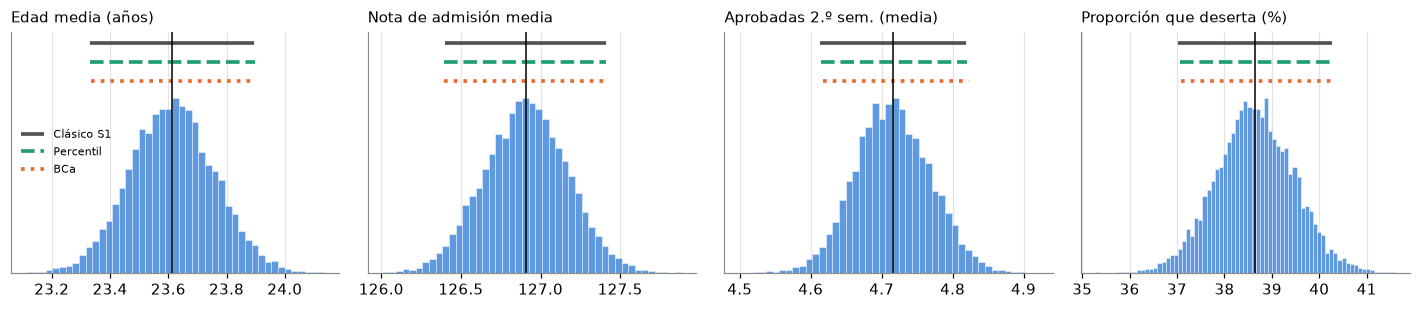

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(13, 2.9))
etiquetas = ['Edad media (años)', 'Nota de admisión media', 'Aprobadas 2.º sem. (media)', 'Proporción que deserta (%)']
for ax, (nombre, _, prop), etq in zip(axes, PARAMETROS, etiquetas):
    r = BOOT[nombre]; esc = 100 if prop else 1
    if prop:
        paso = 3 / len(r['x']); bins = np.arange(r['reps'].min() - paso / 2, r['reps'].max() + paso, paso) * esc
    else:
        bins = 45
    alto, _, _ = ax.hist(r['reps'] * esc, bins=bins, color=AZUL, alpha=0.75, edgecolor='white', linewidth=0.4)
    ymax = alto.max() * 1.35; ax.set_ylim(0, ymax * 1.02)
    for (lo, hi), col, ls, y, txt in [(r['clasico'], GRIS, '-', 0.97, 'Clásico S1'),
                                      (r['percentil'], VERDE, '--', 0.89, 'Percentil'),
                                      (r['bca'], NARANJA, ':', 0.81, 'BCa')]:
        ax.plot([lo * esc, hi * esc], [ymax * y] * 2, color=col, lw=2.4, ls=ls, label=txt, solid_capstyle='butt')
    ax.axvline(r['est'] * esc, color='black', lw=1)
    ax.set_title(etq, fontsize=9.5); ax.set_yticks([]); ax.grid(axis='y', visible=False)
axes[0].legend(fontsize=7.5, loc='center left', frameon=False)
plt.tight_layout(); plt.savefig(f'{FIG}/s2_fig1_bootstrap.png'); plt.show()

## 2. Validación de pruebas de hipótesis de S1 con permutación (ID2.1)

Bajo H₀ las etiquetas de grupo son intercambiables: se barajan **10.000 veces**, se recalcula el estadístico y el
valor *p* de permutación es la proporción de réplicas al menos tan extremas como la observada,
$p = (\#\{|T^*| \ge |T_{obs}|\} + 1)/(B + 1)$ (Good, 2005). Se validan tres pruebas de S1:

1. **Prueba 1 de S1** (*t* de Welch): diferencia de medias de unidades aprobadas en el 2.º semestre.
2. **Prueba 3 de S1** (χ²): beca y deserción; estadístico = diferencia de proporciones de deserción.
3. **Comprobación MCAR de S1** (χ², *p* = 0,041): faltante de la nota de admisión frente a `Target` (3 clases, 4.424
   registros). Es el caso interesante, porque su *p* paramétrico está cerca de α.

In [7]:
def p_perm(nulos, obs):
    return (np.sum(np.abs(nulos) >= abs(obs)) + 1) / (len(nulos) + 1)

rng = np.random.default_rng(SEMILLA)
PERM = {}

# --- Prueba 1: diferencia de medias (Dropout - Graduate) de unidades aprobadas 2.º sem.
y = df[APR2].to_numpy(float); g = df[OBJETIVO].to_numpy()
n1 = g.sum(); tot = y.sum()
obs = y[g == 1].mean() - y[g == 0].mean()
nulos = np.empty(B)
for j in range(B):
    s1 = y[rng.permutation(n)[:n1]].sum()
    nulos[j] = s1 / n1 - (tot - s1) / (n - n1)
t_w = stats.ttest_ind(y[g == 1], y[g == 0], equal_var=False)
PERM['Prueba 1 (Welch, aprobadas 2.º sem.)'] = dict(obs=obs, nulos=nulos, p_perm=p_perm(nulos, obs), p_param=t_w.pvalue)

# --- Prueba 3: diferencia de proporciones de deserción (sin beca - con beca)
bec = df[BECA].to_numpy(); d = df[OBJETIVO].to_numpy(float)
nb = bec.sum(); totd = d.sum()
obs = d[bec == 0].mean() - d[bec == 1].mean()
nulos = np.empty(B)
for j in range(B):
    s_b = d[rng.permutation(n)[:nb]].sum()
    nulos[j] = (totd - s_b) / (n - nb) - s_b / nb
chi2_b, p_b, _, _ = stats.chi2_contingency(pd.crosstab(df[BECA], df[OBJETIVO]), correction=False)
PERM['Prueba 3 (χ², beca)'] = dict(obs=obs, nulos=nulos, p_perm=p_perm(nulos, obs), p_param=p_b)

# --- Comprobación MCAR: χ² entre faltante de la nota de admisión y Target (3 clases)
marca = df_completo[ADM].isna().to_numpy().astype(int)
clase = pd.Categorical(df_completo['Target']).codes; K = clase.max() + 1
tam_clase = np.bincount(clase, minlength=K); N = len(marca); m1 = marca.sum()
def chi2_marca(mk):
    o1 = np.bincount(clase[mk == 1], minlength=K); o0 = tam_clase - o1
    e1 = tam_clase * m1 / N; e0 = tam_clase * (N - m1) / N
    return ((o1 - e1) ** 2 / e1).sum() + ((o0 - e0) ** 2 / e0).sum()
obs = chi2_marca(marca)
nulos = np.array([chi2_marca(rng.permutation(marca)) for _ in range(B)])
p_param = stats.chi2.sf(obs, K - 1)
PERM['Comprobación MCAR (χ², nota de admisión)'] = dict(obs=obs, nulos=nulos,
                                                       p_perm=(np.sum(nulos >= obs) + 1) / (B + 1), p_param=p_param)

tabla_perm = pd.DataFrame({k: {'Estadístico observado': v['obs'], 'p paramétrico (S1)': v['p_param'],
                               'p permutación': v['p_perm'], 'Réplicas tan extremas': int(np.sum(np.abs(v['nulos']) >= abs(v['obs']))),
                               'Rango nulo inf.': v['nulos'].min(), 'Rango nulo sup.': v['nulos'].max()}
                           for k, v in PERM.items()}).T
tabla_perm

,Estadístico observado,p paramétrico (S1),p permutación,Réplicas tan extremas,Rango nulo inf.,Rango nulo sup.
"Prueba 1 (Welch, aprobadas 2.º sem.)",-4.342756,0.000000e+00,0.000100,0.0,-0.374962,0.404773
"Prueba 3 (χ², beca)",0.348409,7.670983e-78,0.000100,0.0,-0.068427,0.071007
"Comprobación MCAR (χ², nota de admisión)",6.395772,4.084847e-02,0.039696,396.0,0.002467,16.474046


In [8]:
# Error estándar Monte Carlo del p de permutación de la comprobación MCAR (¿10.000 permutaciones bastan?)
pm = PERM['Comprobación MCAR (χ², nota de admisión)']['p_perm']
print(f'p permutación MCAR = {pm:.4f}  ± {1.96 * np.sqrt(pm * (1 - pm) / B):.4f} (IC 95 % Monte Carlo)')

p permutación MCAR = 0.0397  ± 0.0038 (IC 95 % Monte Carlo)


### Figura 2 - Distribuciones nulas de permutación

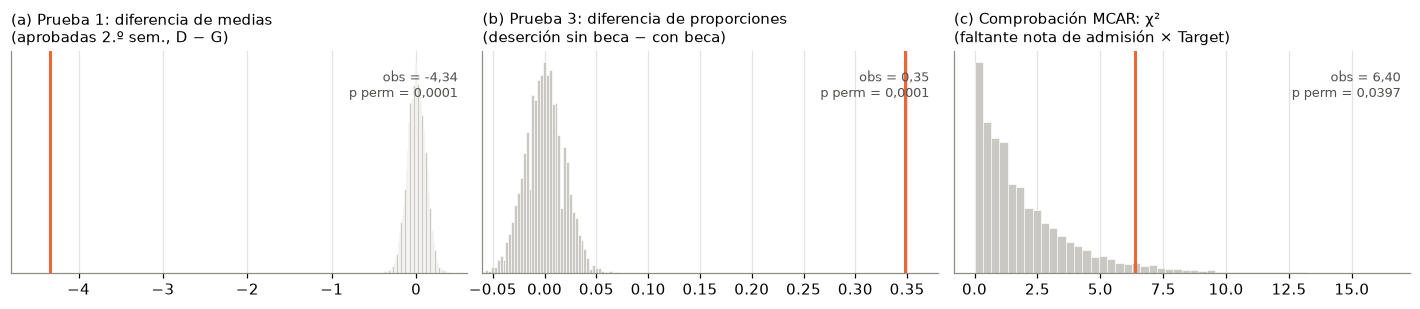

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 2.9))
titulos = ['(a) Prueba 1: diferencia de medias\n(aprobadas 2.º sem., D − G)', '(b) Prueba 3: diferencia de proporciones\n(deserción sin beca − con beca)',
           '(c) Comprobación MCAR: χ²\n(faltante nota de admisión × Target)']
for ax, (k, v), tit in zip(axes, PERM.items(), titulos):
    ax.hist(v['nulos'], bins=50, color='#c9c8c3', edgecolor='white', linewidth=0.4)
    ax.axvline(v['obs'], color=NARANJA, lw=2)
    ax.set_title(tit, fontsize=9.5); ax.set_yticks([]); ax.grid(axis='y', visible=False)
    ax.text(0.98, 0.92, f"obs = {coma(v['obs'], 2)}\np perm = {coma(v['p_perm'], 4)}", transform=ax.transAxes,
            ha='right', va='top', fontsize=8.5, color=GRIS)
axes[0].set_xlim(-4.8, 0.6); axes[1].set_xlim(-0.06, 0.38)
plt.tight_layout(); plt.savefig(f'{FIG}/s2_fig2_permutacion.png'); plt.show()

## 3. Estabilidad de correlaciones de S1 (ID2.1)

Cinco correlaciones de Pearson de la matriz de S1 (Figura 4 del informe de S1), con IC *bootstrap* percentil al 95 %
(10.000 remuestras de filas, casos disponibles por par). Una correlación es **robusta** si su intervalo es estrecho y
no incluye el cero; **inestable** si lo incluye o si su amplitud es grande respecto del valor.

In [10]:
def boot_corr(x, y, rng, B=B, lote=500):
    nn = len(x); rs = np.empty(B); hechas = 0
    while hechas < B:
        b = min(lote, B - hechas); idx = rng.integers(0, nn, size=(b, nn))
        xs, ys = x[idx], y[idx]
        xs = xs - xs.mean(axis=1, keepdims=True); ys = ys - ys.mean(axis=1, keepdims=True)
        rs[hechas:hechas + b] = (xs * ys).sum(axis=1) / np.sqrt((xs ** 2).sum(axis=1) * (ys ** 2).sum(axis=1)); hechas += b
    return rs

PARES = [('Aprobadas 2.º sem. – deserción', APR2, OBJETIVO),
         ('Aprobadas 1.er – 2.º sem.', APR1, APR2),
         ('Nota 2.º sem. (sin ceros) – deserción', NOTA2, OBJETIVO),
         ('Edad – deserción', EDAD, OBJETIVO),
         ('Tasa de desempleo – deserción', DESEMP, OBJETIVO)]
rng = np.random.default_rng(SEMILLA)
CORR, filas = {}, []
for nombre, a_, b_ in PARES:
    s = df[[a_, b_]].dropna().to_numpy(float); x, y = s[:, 0], s[:, 1]
    r0 = np.corrcoef(x, y)[0, 1]; rs = boot_corr(x, y, rng); lo, hi = np.percentile(rs, [2.5, 97.5])
    CORR[nombre] = dict(r=r0, rs=rs, lo=lo, hi=hi)
    filas.append({'Par': nombre, 'n': len(x), 'r (S1)': r0, 'IC inf.': lo, 'IC sup.': hi, 'Amplitud': hi - lo,
                  'Incluye 0': lo <= 0 <= hi, 'Estado': 'Inestable' if lo <= 0 <= hi else 'Robusta'})
tabla_corr = pd.DataFrame(filas).set_index('Par')
tabla_corr.round(4)

,n,r (S1),IC inf.,IC sup.,Amplitud,Incluye 0,Estado
Par,,,,,,,
Aprobadas 2.º sem. – deserción,3478,-0.6859,-0.7077,-0.6636,0.0441,False,Robusta
Aprobadas 1.er – 2.º sem.,3478,0.9079,0.8991,0.9162,0.0171,False,Robusta
Nota 2.º sem. (sin ceros) – deserción,2828,-0.3327,-0.3681,-0.2966,0.0716,False,Robusta
Edad – deserción,3072,0.2857,0.2514,0.3204,0.0690,False,Robusta
Tasa de desempleo – deserción,3478,-0.0069,-0.0414,0.0264,0.0678,True,Inestable


### Figura 3 - Distribuciones *bootstrap* de las correlaciones

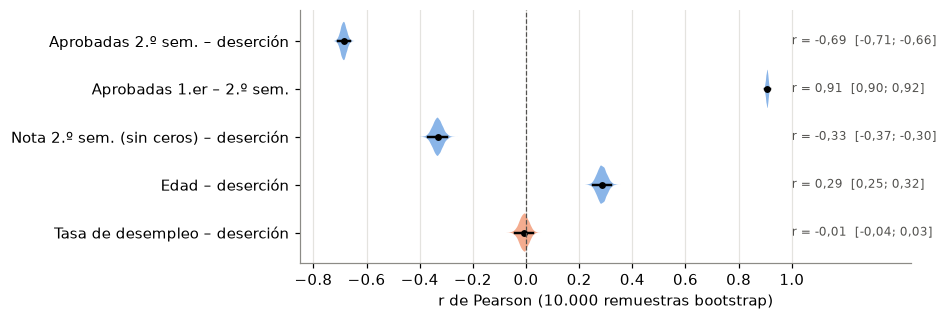

In [11]:
fig, ax = plt.subplots(figsize=(8.5, 3.0))
nombres = list(CORR)[::-1]
import matplotlib
horiz = {'orientation': 'horizontal'} if tuple(map(int, matplotlib.__version__.split('.')[:2])) >= (3, 10) else {'vert': False}
partes = ax.violinplot([CORR[k]['rs'] for k in nombres], showextrema=False, widths=0.8, **horiz)
for cuerpo, k in zip(partes['bodies'], nombres):
    inestable = CORR[k]['lo'] <= 0 <= CORR[k]['hi']
    cuerpo.set_facecolor(NARANJA if inestable else AZUL); cuerpo.set_alpha(0.55); cuerpo.set_edgecolor('none')
for i, k in enumerate(nombres, start=1):
    c = CORR[k]
    ax.plot([c['lo'], c['hi']], [i, i], color='black', lw=1.6); ax.plot(c['r'], i, 'o', color='black', ms=3.5)
    ax.text(1.0, i, f"r = {coma(c['r'], 2)}  [{coma(c['lo'], 2)}; {coma(c['hi'], 2)}]", va='center', fontsize=8, color=GRIS)
ax.axvline(0, color=GRIS, lw=0.8, ls='--')
ax.set_yticks(range(1, len(nombres) + 1)); ax.set_yticklabels(nombres)
ax.set_xlim(-0.85, 1.45); ax.set_xticks(np.arange(-0.8, 1.01, 0.2)); ax.set_xlabel('r de Pearson (10.000 remuestras bootstrap)')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.savefig(f'{FIG}/s2_fig3_correlaciones.png'); plt.show()

## 4. Simulación Monte Carlo con parámetros de S1 (ID2.1 e ID2.3)

**Decisión que apoya:** cuántos cupos de tutoría reservar para una cohorte de ingreso. Si se planifica con el promedio
y la cohorte resulta peor, quedan estudiantes en riesgo sin apoyo.

**Modelo** (solo parámetros estimados en S1, Prueba 3 y Tabla 3): cada estudiante de una cohorte de $N = 1.000$
tiene beca con probabilidad $q = 0{,}2674$ (930 de 3.478) y deserta con la tasa que S1 estimó para su grupo:
$p_{beca} = 0{,}1312$ (122 de 930) y $p_{sin} = 0{,}4796$ (1.222 de 2.548). La tasa esperada es
$q\,p_{beca} + (1-q)\,p_{sin}$. Se simulan **10.000 cohortes**:

- **Escenario base:** parámetros fijos en su estimación puntual.
- **Con incertidumbre de parámetros:** en cada iteración $q$, $p_{beca}$ y $p_{sin}$ se extraen de su distribución
  Beta (conteos de S1), propagando la incertidumbre de la estimación (Robert y Casella, 2004).

In [12]:
k_beca, n_beca = int(df.loc[df[BECA] == 1, OBJETIVO].sum()), int((df[BECA] == 1).sum())
k_sin,  n_sin  = int(df.loc[df[BECA] == 0, OBJETIVO].sum()), int((df[BECA] == 0).sum())
q, p_beca, p_sin = n_beca / n, k_beca / n_beca, k_sin / n_sin
teorica = q * p_beca + (1 - q) * p_sin
print(f'Parámetros de S1: q = {q:.4f} ({n_beca}/{n}), p_beca = {p_beca:.4f} ({k_beca}/{n_beca}), p_sin = {p_sin:.4f} ({k_sin}/{n_sin})')
print(f'Tasa esperada teórica = {teorica:.4f}  | tasa observada en S1 = {df[OBJETIVO].mean():.4f}')

def simular(N, B, rng, q=q, p_beca=p_beca, p_sin=p_sin, incertidumbre=False):
    if incertidumbre:
        q_ = rng.beta(n_beca + 1, n - n_beca + 1, B)
        pb_ = rng.beta(k_beca + 1, n_beca - k_beca + 1, B)
        ps_ = rng.beta(k_sin + 1, n_sin - k_sin + 1, B)
    else:
        q_, pb_, ps_ = q, p_beca, p_sin
    con_beca = rng.binomial(N, q_, B)
    desertores = rng.binomial(con_beca, pb_) + rng.binomial(N - con_beca, ps_)
    return desertores / N

N = 1000
rng = np.random.default_rng(SEMILLA)
tasa = simular(N, B, rng)
tasa_inc = simular(N, B, np.random.default_rng(SEMILLA), incertidumbre=True)

def resumen(t):
    lo, hi = np.percentile(t, [2.5, 97.5])
    return {'Media': t.mean(), 'DE': t.std(ddof=1), 'EE Monte Carlo': t.std(ddof=1) / np.sqrt(len(t)),
            'P2,5': lo, 'P97,5': hi, 'P99': np.percentile(t, 99), 'P(tasa > 42 %)': np.mean(t > 0.42)}
tabla_mc = pd.DataFrame({'Base (parámetros fijos)': resumen(tasa), 'Con incertidumbre de parámetros': resumen(tasa_inc)}).T
tabla_mc.round(4)

Parámetros de S1: q = 0.2674 (930/3478), p_beca = 0.1312 (122/930), p_sin = 0.4796 (1222/2548)
Tasa esperada teórica = 0.3864  | tasa observada en S1 = 0.3864


,Media,DE,EE Monte Carlo,"P2,5","P97,5",P99,P(tasa > 42 %)
Base (parámetros fijos),0.3867,0.0153,0.0002,0.357,0.417,0.423,0.0144
Con incertidumbre de parámetros,0.3868,0.0173,0.0002,0.353,0.421,0.427,0.0260


In [13]:
# Cupos de tutoría: ¿cuántos reservar para cubrir la cohorte en el 95 % y el 99 % de los escenarios?
for etiqueta, t in [('Base', tasa), ('Con incertidumbre', tasa_inc)]:
    print(f'{etiqueta:18s}: promedio {t.mean()*N:.0f} desertores | cupos al 95 %: {np.percentile(t, 95)*N:.0f} '
          f'| al 99 %: {np.percentile(t, 99)*N:.0f} | P(> 400) = {np.mean(t*N > 400):.3f}')

Base              : promedio 387 desertores | cupos al 95 %: 412 | al 99 %: 423 | P(> 400) = 0.181
Con incertidumbre : promedio 387 desertores | cupos al 95 %: 415 | al 99 %: 427 | P(> 400) = 0.210


### Convergencia

La media acumulada debe estabilizarse en torno al valor teórico y su banda (±1,96 errores estándar Monte Carlo) debe
estrecharse como $1/\sqrt{B}$ (Ley de los Grandes Números).

In [14]:
iters = np.arange(1, B + 1)
media_acum = np.cumsum(tasa) / iters
de_acum = np.sqrt(np.maximum(np.cumsum(tasa ** 2) / iters - media_acum ** 2, 0))
ee_acum = de_acum / np.sqrt(iters)
for b_ in [100, 1000, 5000, 10000]:
    print(f'B = {b_:>6,}: media = {media_acum[b_-1]:.5f} | EE Monte Carlo = {ee_acum[b_-1]:.5f} | '
          f'error vs teórica = {abs(media_acum[b_-1] - teorica):.5f}')

B =    100: media = 0.38555 | EE Monte Carlo = 0.00169 | error vs teórica = 0.00088
B =  1,000: media = 0.38648 | EE Monte Carlo = 0.00050 | error vs teórica = 0.00005
B =  5,000: media = 0.38659 | EE Monte Carlo = 0.00022 | error vs teórica = 0.00016
B = 10,000: media = 0.38668 | EE Monte Carlo = 0.00015 | error vs teórica = 0.00025


### Figura 4 - Distribución simulada y convergencia

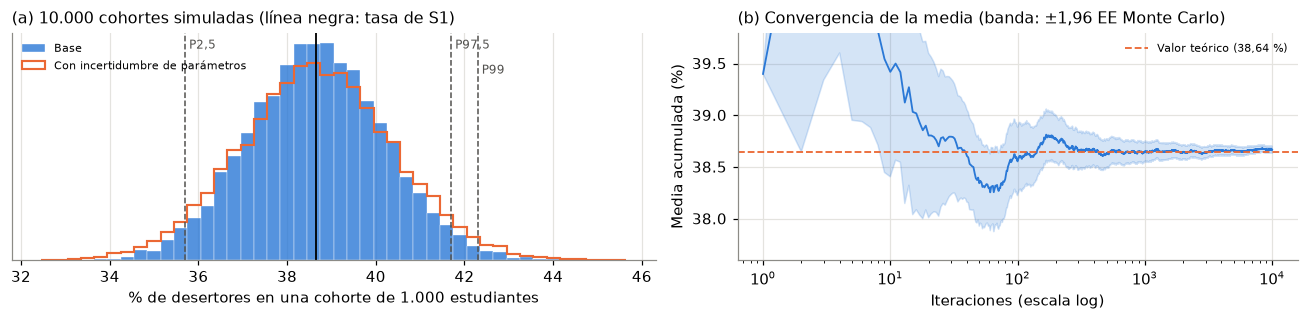

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.0), gridspec_kw={'width_ratios': [1.15, 1]})
ax[0].hist(tasa * 100, bins=np.arange(32.45, 45.7, 0.3), color=AZUL, alpha=0.8, edgecolor='white', linewidth=0.3, label='Base')
ax[0].hist(tasa_inc * 100, bins=np.arange(32.45, 45.7, 0.3), histtype='step', color=NARANJA, lw=1.4, label='Con incertidumbre de parámetros')
lo, hi = np.percentile(tasa, [2.5, 97.5])
for v, txt, yy in [(lo, 'P2,5', 0.97), (hi, 'P97,5', 0.97), (np.percentile(tasa, 99), 'P99', 0.86)]:
    ax[0].axvline(v * 100, color=GRIS, ls='--', lw=1); ax[0].text(v * 100, ax[0].get_ylim()[1] * yy, f' {txt}', fontsize=8, color=GRIS, va='top')
ax[0].axvline(df[OBJETIVO].mean() * 100, color='black', lw=1.2)
ax[0].set_xlabel('% de desertores en una cohorte de 1.000 estudiantes'); ax[0].set_yticks([])
ax[0].set_title('(a) 10.000 cohortes simuladas (línea negra: tasa de S1)'); ax[0].legend(fontsize=7.5, frameon=False, loc='upper left')
ax[1].plot(iters, media_acum * 100, color=AZUL, lw=1.2)
ax[1].fill_between(iters, (media_acum - 1.96 * ee_acum) * 100, (media_acum + 1.96 * ee_acum) * 100, color=AZUL, alpha=0.2)
ax[1].axhline(teorica * 100, color=NARANJA, ls='--', lw=1.2, label=f'Valor teórico ({coma(teorica * 100, 2)} %)')
ax[1].set_xscale('log'); ax[1].set_ylim(37.6, 39.8); ax[1].set_xlabel('Iteraciones (escala log)'); ax[1].set_ylabel('Media acumulada (%)')
ax[1].set_title('(b) Convergencia de la media (banda: ±1,96 EE Monte Carlo)'); ax[1].legend(fontsize=7.5, frameon=False)
plt.tight_layout(); plt.savefig(f'{FIG}/s2_fig4_montecarlo.png'); plt.show()

### 4.1 Análisis de sensibilidad (ID2.3)

1. **Tamaño de la cohorte** ($N$ = 100, 500, 1.000 y 3.000): misma tasa esperada, distinta dispersión.
2. **Sensibilidad de cada entrada:** se mueve un parámetro a cada extremo de su IC 95 % de S1 manteniendo los demás
   fijos y se mide el cambio en la tasa esperada simulada (gráfico de tornado).
3. **Escenario de cobertura de becas** (26,7 % actual, 35 % y 50 %), suponiendo que la tasa de deserción de cada
   grupo se mantiene. Es un escenario exploratorio: la asociación de S1 es observacional y no prueba que la beca
   reduzca la deserción.

In [16]:
filas = []
for Nt in [100, 500, 1000, 3000]:
    t = simular(Nt, B, np.random.default_rng(SEMILLA))
    lo, hi = np.percentile(t, [2.5, 97.5])
    filas.append({'N': Nt, 'Media %': t.mean() * 100, 'P2,5 %': lo * 100, 'P97,5 %': hi * 100,
                  'Amplitud (pp)': (hi - lo) * 100, 'P99 %': np.percentile(t, 99) * 100,
                  'Cupos al 95 %': np.ceil(np.percentile(t, 95) * Nt)})
tabla_N = pd.DataFrame(filas).set_index('N')
tabla_N.round(2)

,Media %,"P2,5 %","P97,5 %",Amplitud (pp),P99 %,Cupos al 95 %
N,,,,,,
100,38.63,29.00,48.00,19.0,50.00,47.0
500,38.65,34.40,43.00,8.6,43.60,211.0
1000,38.67,35.70,41.70,6.0,42.30,412.0
3000,38.65,36.97,40.37,3.4,40.77,1203.0


In [17]:
def ic_prop(k, m):
    p = k / m; ee = np.sqrt(p * (1 - p) / m); return p - 1.96 * ee, p + 1.96 * ee
rangos = {'Proporción con beca (q)': ('q', ic_prop(n_beca, n)),
          'Deserción con beca (p_beca)': ('p_beca', ic_prop(k_beca, n_beca)),
          'Deserción sin beca (p_sin)': ('p_sin', ic_prop(k_sin, n_sin))}
base_media = simular(N, B, np.random.default_rng(SEMILLA)).mean()
filas = []
for etq, (par, (lo, hi)) in rangos.items():
    m_lo = simular(N, B, np.random.default_rng(SEMILLA), **{par: lo}).mean()
    m_hi = simular(N, B, np.random.default_rng(SEMILLA), **{par: hi}).mean()
    filas.append({'Parámetro': etq, 'IC 95 % S1': f'[{lo:.4f}; {hi:.4f}]', 'Tasa con extremo inf. %': m_lo * 100,
                  'Tasa con extremo sup. %': m_hi * 100, 'Rango de impacto (pp)': abs(m_hi - m_lo) * 100})
tornado = pd.DataFrame(filas).set_index('Parámetro').sort_values('Rango de impacto (pp)')
print(f'Tasa base simulada = {base_media * 100:.2f} %')
tornado.round(3)

Tasa base simulada = 38.67 %


,IC 95 % S1,Tasa con extremo inf. %,Tasa con extremo sup. %,Rango de impacto (pp)
Parámetro,,,,
Proporción con beca (q),[0.2527; 0.2821],39.161,38.148,1.013
Deserción con beca (p_beca),[0.1095; 0.1529],38.064,39.247,1.183
Deserción sin beca (p_sin),[0.4602; 0.4990],37.246,40.089,2.843


In [18]:
esc = []
for cobertura in [q, 0.35, 0.50]:
    t = simular(N, B, np.random.default_rng(SEMILLA), q=cobertura)
    esc.append({'Cobertura de becas': cobertura, 'Media %': t.mean() * 100,
                'P2,5 %': np.percentile(t, 2.5) * 100, 'P97,5 %': np.percentile(t, 97.5) * 100,
                'Desertores esperados (N=1.000)': t.mean() * N})
tabla_becas = pd.DataFrame(esc).set_index('Cobertura de becas')
tabla_becas.round(2)

,Media %,"P2,5 %","P97,5 %",Desertores esperados (N=1.000)
Cobertura de becas,,,,
0.267395,38.67,35.7,41.7,386.68
0.350000,35.79,32.9,38.8,357.87
0.500000,30.55,27.8,33.4,305.53


### Figura 5 - Sensibilidad: tamaño de cohorte y parámetros de entrada

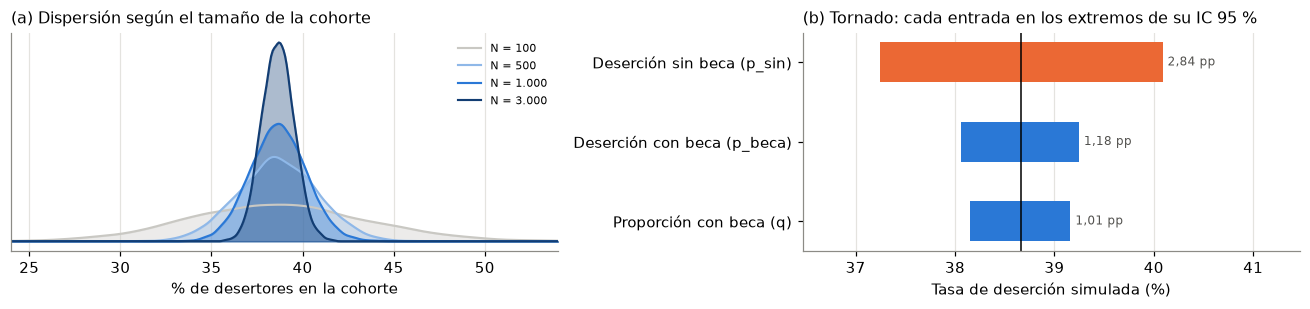

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 2.9), gridspec_kw={'width_ratios': [1.1, 1]})
for Nt, col in zip([100, 500, 1000, 3000], ['#c9c8c3', '#8fb8e8', AZUL, '#123d73']):
    t = simular(Nt, B, np.random.default_rng(SEMILLA)) * 100
    xs = np.linspace(22, 56, 400); dens = stats.gaussian_kde(t)(xs)
    ax[0].fill_between(xs, dens, color=col, alpha=0.35); ax[0].plot(xs, dens, color=col, lw=1.4, label=f'N = {coma(Nt, 0)}')
ax[0].set_xlim(24, 54); ax[0].set_yticks([]); ax[0].set_xlabel('% de desertores en la cohorte')
ax[0].set_title('(a) Dispersión según el tamaño de la cohorte'); ax[0].legend(fontsize=7.5, frameon=False)
yy = np.arange(len(tornado))
for i, (etq, f) in enumerate(tornado.iterrows()):
    lo_, hi_ = sorted([f['Tasa con extremo inf. %'], f['Tasa con extremo sup. %']])
    ax[1].barh(i, hi_ - lo_, left=lo_, color=NARANJA if i == len(tornado) - 1 else AZUL, height=0.5)
    ax[1].text(hi_ + 0.05, i, f"{coma(f['Rango de impacto (pp)'], 2)} pp", va='center', fontsize=8, color=GRIS)
ax[1].axvline(base_media * 100, color='black', lw=1)
ax[1].set_yticks(yy); ax[1].set_yticklabels(tornado.index); ax[1].set_xlabel('Tasa de deserción simulada (%)')
ax[1].set_title('(b) Tornado: cada entrada en los extremos de su IC 95 %'); ax[1].grid(axis='y', visible=False)
ax[1].set_xlim(base_media * 100 - 2.2, base_media * 100 + 2.8)
plt.tight_layout(); plt.savefig(f'{FIG}/s2_fig5_sensibilidad.png'); plt.show()

## 5. Análisis de robustez (ID2.2 e ID2.3)

1. **Valores extremos en la edad** (la variable más asimétrica de S1: asimetría 1,97, curtosis 3,72): *jackknife*,
   media recortada, media sin el 1 % superior y mediana.
2. **Decisión de excluir los 152 registros sin actividad** (S1): efecto sobre las cifras principales.
3. **Datos faltantes MCAR:** estimaciones con casos disponibles frente a los valores originales guardados.
4. **Datos sintéticos (ID2.2):** cobertura real del IC *t* de S1 cuando la variable es tan asimétrica como la edad,
   para distintos tamaños de muestra.

In [20]:
x = df[EDAD].dropna().to_numpy(float); nn = len(x)
jack = (x.sum() - x) / (nn - 1)
ee_jack = np.sqrt((nn - 1) / nn * ((jack - jack.mean()) ** 2).sum())
influencia = (nn - 1) * (x.mean() - jack)             # efecto de cada observación en la media
i_max = np.argmax(np.abs(influencia))
rob_edad = pd.Series({
    'Media (S1)': x.mean(), 'Media recortada 5 %': stats.trim_mean(x, 0.05),
    'Media sin el 1 % superior': x[x <= np.percentile(x, 99)].mean(), 'Mediana': np.median(x),
    'EE clásico': x.std(ddof=1) / np.sqrt(nn), 'EE jackknife': ee_jack,
    'Observación más influyente (edad)': x[i_max], 'Cambio en la media al quitarla': x.mean() - jack[i_max],
    'Estudiantes con 40 años o más': int((x >= 40).sum())}, dtype=object)
rob_edad

Media (S1)                           23.612956
Media recortada 5 %                  22.573391
Media sin el 1 % superior            23.310447
Mediana                                   20.0
EE clásico                            0.142921
EE jackknife                          0.142921
Observación más influyente (edad)         70.0
Cambio en la media al quitarla        0.015105
Estudiantes con 40 años o más              186
dtype: object

In [21]:
def d_cohen(a, b):
    na, nb_ = len(a), len(b); s = np.sqrt(((na - 1) * a.var(ddof=1) + (nb_ - 1) * b.var(ddof=1)) / (na + nb_ - 2))
    return (a.mean() - b.mean()) / s

def cifras(d):
    a, b = d.loc[d[OBJETIVO] == 1, APR2], d.loc[d[OBJETIVO] == 0, APR2]
    tb = d.groupby(BECA)[OBJETIVO].mean()
    return {'n': len(d), '% deserción': d[OBJETIVO].mean() * 100, 'd de Cohen (Prueba 1)': d_cohen(a, b),
            't de Welch': stats.ttest_ind(a, b, equal_var=False).statistic,
            'Deserción sin beca %': tb[0] * 100, 'Deserción con beca %': tb[1] * 100,
            'r aprobadas 2.º – deserción': d[[APR2, OBJETIVO]].corr().iloc[0, 1]}
tabla_exclusion = pd.DataFrame({'Con los 152 registros': cifras(preparar(df_completo, excluir_sin_actividad=False)),
                                'Sin ellos (S1)': cifras(df)}).T
tabla_exclusion.round(3)

,n,% deserción,d de Cohen (Prueba 1),t de Welch,Deserción sin beca %,Deserción con beca %,r aprobadas 2.º – deserción
Con los 152 registros,3630.0,39.146,-1.771,-50.671,48.365,13.829,-0.654
Sin ellos (S1),3478.0,38.643,-1.935,-52.330,47.959,13.118,-0.686


In [22]:
# Faltantes MCAR: se reconstruye la variable completa con los valores originales guardados y se compara
filas = []
for col in [EDAD, ADM]:
    completo = df_completo.set_index('id_estudiante')[col].copy()
    o = originales[originales['variable'] == col].set_index('id_estudiante')['valor_original']
    completo.loc[o.index] = o.values
    completo = completo.loc[df['id_estudiante']]
    disp = df[col].dropna()
    filas.append({'Variable': col, 'Media casos disponibles': disp.mean(), 'n disponibles': len(disp),
                  'Media con valores originales': completo.mean(), 'n completo': len(completo),
                  'Diferencia': disp.mean() - completo.mean(),
                  'Diferencia / EE': (disp.mean() - completo.mean()) / (disp.std(ddof=1) / np.sqrt(len(disp)))})
tabla_mcar = pd.DataFrame(filas).set_index('Variable')
tabla_mcar.round(4)

,Media casos disponibles,n disponibles,Media con valores originales,n completo,Diferencia,Diferencia / EE
Variable,,,,,,
Age at enrollment,23.6130,3072,23.5969,3478,0.0161,0.1124
Admission grade,126.9073,3041,126.9135,3478,-0.0062,-0.0241


### 5.1 Datos sintéticos: ¿es confiable el IC *t* de S1 con una variable tan asimétrica? (ID2.2)

Se generan dos **poblaciones sintéticas** de edades (1.000.000 de valores cada una) con los métodos del apunte de
datos sintéticos:

- **Paramétrica:** distribución Gamma ajustada por máxima verosimilitud a la edad observada.
- **Perturbación:** cada valor sintético es una edad observada más un ruido uniforme de ±0,5 años (la edad viene en
  años enteros).

Su fidelidad se valida con la prueba de Kolmogorov-Smirnov (sobre valores redondeados al año, porque la edad
observada es entera), la distancia de Wasserstein y los momentos. Luego se extraen **10.000 muestras** de cada tamaño
y se mide qué proporción de los IC *t* al 95 % contiene la media real de la población sintética (cobertura empírica).

In [23]:
rng = np.random.default_rng(SEMILLA)
x = df[EDAD].dropna().to_numpy(float)
a_g, loc_g, esc_g = stats.gamma.fit(x)
POB = {'Paramétrica (Gamma)': stats.gamma.rvs(a_g, loc=loc_g, scale=esc_g, size=1_000_000, random_state=rng),
       'Perturbación (±0,5 años)': rng.choice(x, 1_000_000) + rng.uniform(-0.5, 0.5, 1_000_000)}
fidelidad = {'Observada (S1)': {'Media': x.mean(), 'Mediana': np.median(x), 'Desv. est.': x.std(ddof=1),
                                'Asimetría': stats.skew(x), 'Curtosis': stats.kurtosis(x)}}
for nombre, pob in POB.items():
    ks = stats.ks_2samp(x, np.round(rng.choice(pob, len(x), replace=False)))
    fidelidad[nombre] = {'Media': pob.mean(), 'Mediana': np.median(pob), 'Desv. est.': pob.std(),
                         'Asimetría': stats.skew(pob), 'Curtosis': stats.kurtosis(pob),
                         'KS (D)': ks.statistic, 'KS (p)': ks.pvalue,
                         'Wasserstein (años)': stats.wasserstein_distance(x, pob[:200_000])}
print(f'Gamma ajustada: forma = {a_g:.3f}, desplazamiento = {loc_g:.2f}, escala = {esc_g:.3f}')
pd.DataFrame(fidelidad).round(3)

Gamma ajustada: forma = 0.949, desplazamiento = 17.00, escala = 7.053


,Observada (S1),Paramétrica (Gamma),"Perturbación (±0,5 años)"
Media,23.613,23.700,23.618
Mediana,20.000,21.551,20.024
Desv. est.,7.921,6.879,7.937
Asimetría,1.965,2.062,1.965
Curtosis,3.714,6.447,3.729
KS (D),NaN,0.150,0.013
KS (p),NaN,0.000,0.947
Wasserstein (años),NaN,1.291,0.252


In [24]:
rng = np.random.default_rng(SEMILLA)
filas = []
for m in [15, 30, 100, 500, 3072]:
    fila = {'Tamaño de muestra': m}
    for nombre, pob in POB.items():
        mu = pob.mean(); cubre, hechas, lote = 0, 0, max(1, 2_000_000 // m)
        while hechas < B:
            b = min(lote, B - hechas)
            s = rng.choice(pob, size=(b, m), replace=True)
            med, ee = s.mean(axis=1), s.std(axis=1, ddof=1) / np.sqrt(m)
            tq = stats.t.ppf(0.975, m - 1)
            cubre += np.sum((med - tq * ee <= mu) & (mu <= med + tq * ee)); hechas += b
        fila[f'Cobertura {nombre}'] = cubre / B
    filas.append(fila)
tabla_cobertura = pd.DataFrame(filas).set_index('Tamaño de muestra')
print(f'EE Monte Carlo de una cobertura de 0,95 con B = {B:,}: {np.sqrt(0.95 * 0.05 / B):.4f}')
tabla_cobertura.round(4)

EE Monte Carlo de una cobertura de 0,95 con B = 10,000: 0.0022


,Cobertura Paramétrica (Gamma),"Cobertura Perturbación (±0,5 años)"
Tamaño de muestra,,
15,0.9064,0.8921
30,0.9270,0.9198
100,0.9390,0.9380
500,0.9482,0.9487
3072,0.9502,0.9495


## 6. Reporte de resultados validados para la Sumativa 3

Se consolida qué resultados de S1 quedaron validados y cuáles requieren cautela, y se guarda como archivo aparte
(`data/processed/resultados_validados.csv`), que es la entrada directa de la Sumativa 3.

In [25]:
f = lambda v, d=2: coma(v, d)
tb = tabla_boot; pm_ = PERM
validados = pd.DataFrame([
    ['Parámetro', 'Proporción que deserta', f(S1['Proporción que deserta'][0] * 100) + ' %',
     f"Clásico, percentil y BCa coinciden; Monte Carlo la reproduce ({f(tasa.mean() * 100)} %)", 'Robusto'],
    ['Parámetro', 'Nota de admisión media', f(S1['Nota de admisión media'][0]),
     'Clásico, percentil y BCa coinciden; faltantes MCAR no la sesgan', 'Robusto'],
    ['Parámetro', 'Unidades aprobadas medias, 2.º sem.', f(S1['Unidades aprobadas medias, 2.º sem.'][0]),
     'Clásico, percentil y BCa coinciden', 'Robusto'],
    ['Parámetro', 'Edad media al ingresar', f(S1['Edad media al ingresar (años)'][0]),
     f"IC estable (BCa se corre {f(tb.loc['Edad media al ingresar (años)', 'Máx. desplazamiento BCa vs clásico'], 3)} años), "
     f"pero la media baja a {f(rob_edad['Media recortada 5 %'])} al recortar 5 %; mediana 20", 'Cautela: usar mediana'],
    ['Prueba', 'Prueba 1: aprobadas 2.º sem. (Welch, d = −1,94)', 'p < 0,0001',
     f"Permutación p = {f(pm_['Prueba 1 (Welch, aprobadas 2.º sem.)']['p_perm'], 4)}; ninguna réplica tan extrema", 'Robusto'],
    ['Prueba', 'Prueba 3: beca y deserción (χ², V = 0,32)', 'p < 0,0001',
     f"Permutación p = {f(pm_['Prueba 3 (χ², beca)']['p_perm'], 4)}", 'Robusto'],
    ['Prueba', 'Comprobación MCAR (χ², p = 0,041)', 'p = 0,041',
     f"Permutación p = {f(pm_['Comprobación MCAR (χ², nota de admisión)']['p_perm'], 3)}: confirma un falso positivo límite", 'Cautela: error tipo I'],
] + [['Correlación', k, f(v['r']), f"IC bootstrap [{f(v['lo'])}; {f(v['hi'])}]",
      'Inestable (incluye 0)' if v['lo'] <= 0 <= v['hi'] else 'Robusta'] for k, v in CORR.items()] + [
    ['Observaciones influyentes', 'Edades extremas (40 años o más)', str(rob_edad['Estudiantes con 40 años o más']),
     f"Observación más influyente: {int(rob_edad['Observación más influyente (edad)'])} años", 'Documentado'],
    ['Observaciones influyentes', '152 registros sin actividad académica', '152 excluidos',
     f"Con ellos d = {f(tabla_exclusion.iloc[0]['d de Cohen (Prueba 1)'])}; sin ellos {f(tabla_exclusion.iloc[1]['d de Cohen (Prueba 1)'])}", 'Mantener exclusión'],
], columns=['Tipo', 'Resultado de S1', 'Valor S1', 'Validación en S2', 'Estado'])
validados.to_csv('../data/processed/resultados_validados.csv', index=False, encoding='utf-8-sig')
validados

,Tipo,Resultado de S1,Valor S1,Validación en S2,Estado
0,Parámetro,Proporción que deserta,"38,64 %","Clásico, percentil y BCa coinciden; Monte Carl...",Robusto
1,Parámetro,Nota de admisión media,"126,91","Clásico, percentil y BCa coinciden; faltantes ...",Robusto
2,Parámetro,"Unidades aprobadas medias, 2.º sem.","4,72","Clásico, percentil y BCa coinciden",Robusto
3,Parámetro,Edad media al ingresar,"23,61","IC estable (BCa se corre 0,009 años), pero la ...",Cautela: usar mediana
4,Prueba,"Prueba 1: aprobadas 2.º sem. (Welch, d = −1,94)","p < 0,0001","Permutación p = 0,0001; ninguna réplica tan ex...",Robusto
5,Prueba,"Prueba 3: beca y deserción (χ², V = 0,32)","p < 0,0001","Permutación p = 0,0001",Robusto
6,Prueba,"Comprobación MCAR (χ², p = 0,041)","p = 0,041","Permutación p = 0,040: confirma un falso posit...",Cautela: error tipo I
7,Correlación,Aprobadas 2.º sem. – deserción,"-0,69","IC bootstrap [-0,71; -0,66]",Robusta
8,Correlación,Aprobadas 1.er – 2.º sem.,"0,91","IC bootstrap [0,90; 0,92]",Robusta
9,Correlación,Nota 2.º sem. (sin ceros) – deserción,"-0,33","IC bootstrap [-0,37; -0,30]",Robusta


### Recomendaciones metodológicas para la Sumativa 3

- **Variable objetivo y muestra:** mantener Dropout (1) frente a Graduate (0), sin Enrolled ni los 152 registros sin
  actividad (n = 3.478; 38,6 % de desertores, clases moderadamente desbalanceadas).
- **Multicolinealidad:** las unidades aprobadas del 1.er y del 2.º semestre tienen r = 0,91 con IC *bootstrap*
  estrecho; no incluirlas juntas en la regresión logística sin revisar el VIF.
- **Fuga de información:** la matrícula al día puede ser consecuencia del abandono; evaluar el modelo con y sin ella.
- **Edad:** asimétrica y con valores extremos influyentes; usar mediana en descripciones y considerar una
  transformación (logaritmo) o tramos en el modelo.
- **Faltantes:** son MCAR (validado por permutación y por comparación con los originales); la imputación de S3 puede
  medirse contra `valores_originales.csv`.
- **Variables débiles:** la tasa de desempleo no muestra asociación estable con la deserción; su aporte debe
  justificarse con el modelo.

In [26]:
print('Archivos generados:')
for ruta in sorted(os.listdir(FIG)):
    print('  docs/figuras/S2/' + ruta)
print('  data/processed/resultados_validados.csv')

Archivos generados:
  docs/figuras/S2/s2_fig1_bootstrap.png
  docs/figuras/S2/s2_fig2_permutacion.png
  docs/figuras/S2/s2_fig3_correlaciones.png
  docs/figuras/S2/s2_fig4_montecarlo.png
  docs/figuras/S2/s2_fig5_sensibilidad.png
  data/processed/resultados_validados.csv
